In [36]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
def f(x):
  return 3*x**2 - 4*x + 5

In [38]:
f(3.0)

20.0

In [39]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

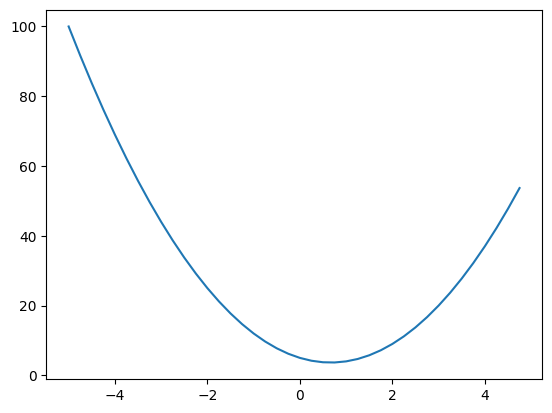

In [40]:
plt.plot(xs,ys)

In [41]:
#This is the basis of the derivative and here we are learning about the basics of the derivation of a function
h = 0.00000001
x = 3.0
(f(x + h) - f(x))/h

14.00000009255109

In [42]:
#For the case of x = 2/3, the value of the derivative of the function is 0.
h = 0.00000001
x = 2/3
(f(x + h) - f(x))/h

0.0

In [43]:
#Example - 1, For the more COMPLEX CASES
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [44]:
h = 0.00001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c
print('d1', d1)
print('d2', d2) #Since a negative number -3 is being multiplied with 'a', hence the overall value of d2 is less than d1.
#As being metioned above the slope of the function wrt a is negative.
print("Solpe is: ", (d2-d1)/h)

d1 4.0
d2 3.9999699999999994
Solpe is:  -3.000000000064062


In [45]:
#Let us find the derivative wrt b
h = 0.00001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
b += h
d2 = a*b + c
print('d1', d1)
print('d2', d2) #Since a negative number positve is being added into a negative, hence the value of the negative reduces, making the slope positive.
#As being metioned above the slope of the function wrt b is positive.
print("Solpe is: ", (d2-d1)/h)

d1 4.0
d2 4.00002
Solpe is:  2.0000000000131024


In [46]:
#Let us find the derivative wrt c
h = 0.00001

a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)
#The slope is: -
print("Solpe is: ", (d2-d1)/h)

d1 4.0
d2 4.00001
Solpe is:  0.9999999999621422


In [213]:
#As we were doing the things above in a more specific manner and with the help of variables, will make a class here for the whole bunch of variables.
class Value:

  def __init__(self, data, _children=(), _op=(), label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None #This is doing nothing here: - ??
    self._prev = set(_children) #Here, children(), is one of the tuple that is having the information of previously operated values.
    self._op = _op #Here, op() is the tuple having the information regarding the operator that is being used for the operation of the values.
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})" #The syntax = This is printing the "Value(data={Here it is going to print the data of the variable})"

  def __add__(self, other):
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      #This is the grad cal for the addition, as value of the self grad is 1 * grad of the further node.
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out

  def __mul__(self, other):
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      #This is the grad cal for the multiplication, and uses the similar concept as it is being mentioned below: -
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
      #The value of out.grad for each of the case is 0.0 and need to be modified before the changes.
    out._backward = _backward

    return out

#Here, I am defining the topological sort, with the help of the same can run the backpropogation in the loop, automating the things: -
  def backward(self):
    topo = []
    visited = set()
    def build_topo (v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed (topo):
      node._backward()

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f') #What is the reason for the mentioning of -2 here?
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [214]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [69]:
d._op #Here, '+' iss coming, since the last operator was a plus, for the addition of a*b "+"" c.

'+'

In [70]:
a+b

Value(data=-1.0)

In [71]:
a*b + c

Value(data=4.0)

In [72]:
#For the case of visulization of the backpropagation and derivative (grad), this is a set of code for the making of the grapgh, does not have relation with the learning.
from graphviz import Digraph

# 'graphviz' this is one of the free source for the making of the graph, this has been used for the making of the graph: -

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

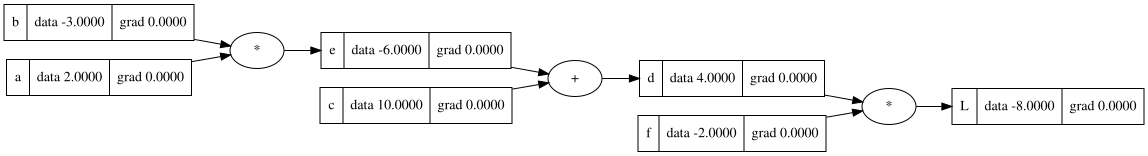

In [159]:
draw_dot(L)

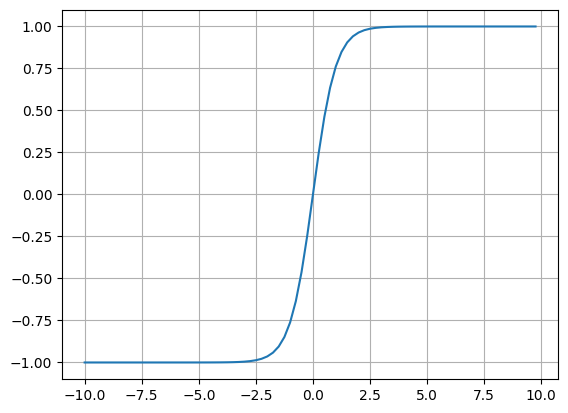

In [83]:
#Here, this is the plot for the ACTIVATION FUNCTION - tanhx()
plt.plot(np.arange(-10, 10, 0.25), np.tanh(np.arange(-10, 10, 0.25)));
plt.grid();

In [215]:
#EXAMPLE - 2 - MANUAL BACKPROPOGATION
# inputs x1,x2
#Here, providing the inputs x1 and x2

x1 = Value (2.0, label='x1')
x2= Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1w1 + x2w2 + b
#Here, each value is being multiplied with a weight (Multiplying input values by weights in a neural network determines the importance and strength of each signal).
#Then a bias is added into the sum(product).

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
# o.backward()

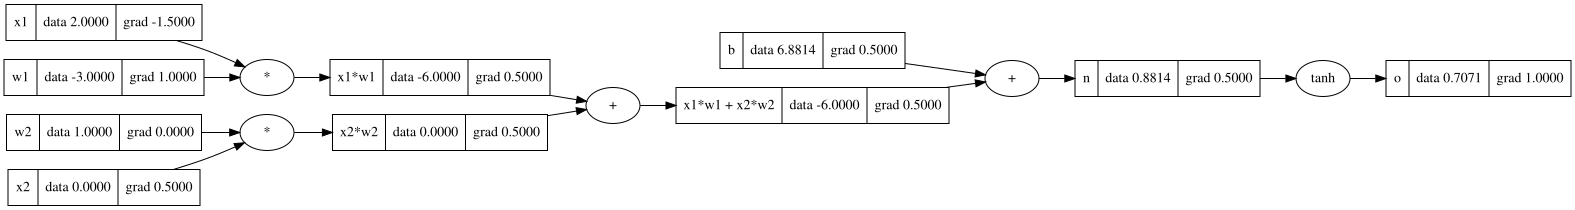

In [217]:
draw_dot(o)

In [216]:
o.backward()

In [147]:
#This is once again we did the backpropogation via the help of the backward() function, not doing the calculation manually - :)
o.grad = 1.0

In [139]:
o._backward()

In [141]:
n._backward()

In [143]:
x1w1x2w2._backward()

In [145]:
x1w1._backward()
x2w2._backward()

In [119]:
#Here for the case of the first two nodes of multiplication, we have to use the same method as it is being used in the previous case, for the finding of the grad.
#w1.grad = x1w1.grad * x1.data
#x1.grad = x1w1.grad * w1.data
#The similar step is used for the other portion also.
w1.grad = 1.0
x1.grad = -1.5
w2.grad = 0.0
x2.grad = 0.5

In [110]:
x1w1.grad = 0.5
x2w2.grad = 0.5

In [108]:
x1w1x2w2.grad = 0.5
b.grad = 0.5

In [106]:
n.grad = 0.5

In [99]:
o.grad = 1.0

-7.286496


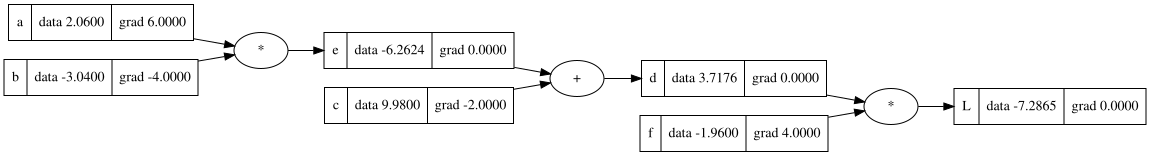

In [79]:
# a.data += 0.01 * a.grad
# b.data += 0.01 * b.grad
# c.data += 0.01 * c.grad
# f.data += 0.01 * f.grad

# #Here, we are giving a positive change to all the data values of the variable hence, expecting a positive change in the value of L -> I should become less negative.

# e = a*b; e.label = 'e'
# d = e + c; d.label = 'd'
# L = d * f; L.label = 'L'
# print(L.data)
draw_dot(L)

In [101]:
a.grad = 6.0
b.grad = -4.0

In [102]:
c.grad = -2.0
e.grad = -2.0

In [103]:
L.grad = 1

In [104]:
f.grad = 4.0
d.grad = -2.0

In [78]:
#This is one of the function that is created for finding of the derivative of the L wrt to any of the variables. Just change the value of the variable by h -> 0.

#Here, we did the derivation of L wrt c and e, this is one of the most imp step for the backpropogation, in the same we have used the main concept of the chain rule.
#dL/de = dL/dd*dd/de -> This is coming from the chain rule.
#As L = d*f and d is a fuction of 'e'.
#dL/de = (-2.0) * (d(e+c)/de = 1)
#dL/de = -2.0

def lol():

  h = 0.001

  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f') #What is the reason for the mentioning of -2 here?
  L = d * f; L.label = 'L'
  L1 = L.data

  a = Value(2.0, label='a')
  b = Value(-3.0 + h, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f') #What is the reason for the mentioning of -2 here?
  L = d * f; L.label = 'L'
  L2 = L.data

  print((L2-L1)/h)

lol()

-3.9999999999995595
